Step 1 — Install and import libraries

In [ ]:
!pip install -q torch torchvision matplotlib pandas

In [ ]:
import os
import random
import copy
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", DEVICE)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA available: True
Selected device: cuda


Step 2 — Reproducibility and configuration

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 0.001

NUM_CLASSES = 10
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

os.makedirs("outputs/checkpoints", exist_ok=True)
os.makedirs("outputs/plots", exist_ok=True)

print("Configuration completed.")

Configuration completed.


Step 3 — CIFAR-10 class names

In [ ]:
CLASS_NAMES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Number of classes:", len(CLASS_NAMES))
print(CLASS_NAMES)

Number of classes: 10
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Step 4 — Data preprocessing and augmentation

In [ ]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

print("Data transformations ready.")

Data transformations ready.


Step 5 — Load dataset and create DataLoaders

In [ ]:
train_dataset_aug = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

train_dataset_eval = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=eval_transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=eval_transform
)

rng = np.random.RandomState(SEED)
indices = rng.permutation(len(train_dataset_aug))

train_indices = indices[:45000].tolist()
val_indices = indices[45000:].tolist()

train_subset = Subset(train_dataset_aug, train_indices)
val_subset = Subset(train_dataset_eval, val_indices)

def get_loaders(batch_size):

    train_loader = DataLoader(
        train_subset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader


train_loader, val_loader = get_loaders(BATCH_SIZE)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Testing images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

100%|██████████| 170M/170M [00:13<00:00, 12.8MB/s]


Training images: 45000
Validation images: 5000
Testing images: 10000
Training batches: 704
Validation batches: 79
Testing batches: 157


Step 6 — Visualize sample images

Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])


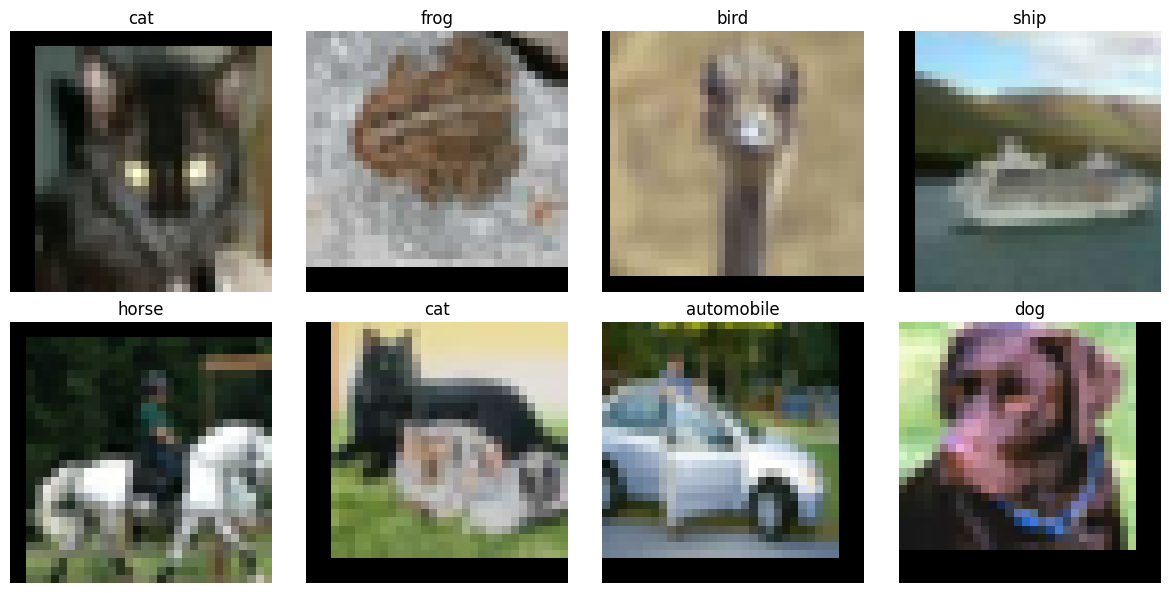

In [ ]:
def show_image_batch(images, labels, max_images=8):

    images = images[:max_images].cpu()
    labels = labels[:max_images].cpu()

    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR_STD).view(3, 1, 1)

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))

    for i, ax in enumerate(axes.flat):

        if i >= len(images):
            ax.axis("off")
            continue

        img = images[i] * std + mean
        img = img.clamp(0, 1).permute(1, 2, 0).numpy()

        ax.imshow(img)
        ax.set_title(CLASS_NAMES[labels[i].item()])
        ax.axis("off")

    plt.tight_layout()
    plt.show()


images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

show_image_batch(images, labels)

Step 7 — Build Baseline CNN model

In [ ]:
class BaselineCNN(nn.Module):

    def __init__(self, num_classes=10, dropout_rate=0.25):

        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),
            nn.Dropout(dropout_rate),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),
            nn.Dropout(dropout_rate),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),
            nn.Dropout(dropout_rate)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),

            nn.Dropout(dropout_rate),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x


baseline_model = BaselineCNN().to(DEVICE)

sample = torch.randn(4, 3, 32, 32).to(DEVICE)

output = baseline_model(sample)

print("Baseline output shape:", output.shape)
print(baseline_model)

Baseline output shape: torch.Size([4, 10])
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13)

Step 8 — Training and validation functions

In [ ]:
def calculate_accuracy(outputs, labels):

    predictions = outputs.argmax(dim=1)

    correct = (predictions == labels).sum().item()

    return correct, labels.size(0)


def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        batch_correct, batch_total = calculate_accuracy(
            outputs, labels
        )

        correct += batch_correct
        total += batch_total

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size

            batch_correct, batch_total = calculate_accuracy(
                outputs, labels
            )

            correct += batch_correct
            total += batch_total

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions ready.")

Training and validation functions ready.


Step 9 — General training function and checkpoint

In [ ]:
def train_model(
    model,
    model_name,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    optimizer_name="Adam",
    early_stopping_patience=None,
    gradient_clip_value=None
):

    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "Adam":

        optimizer = optim.Adam(
            model.parameters(),
            lr=learning_rate
        )

    elif optimizer_name == "SGD":

        optimizer = optim.SGD(
            model.parameters(),
            lr=learning_rate,
            momentum=0.9
        )

    else:

        raise ValueError("Unsupported optimizer: " + optimizer_name)

    scheduler = optim.lr_scheduler.StepLR(
        optimizer,
        step_size=7,
        gamma=0.5
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
        "learning_rate": []
    }

    best_val_accuracy = 0.0
    best_val_loss = float("inf")

    patience_counter = 0

    checkpoint_path = (
        f"outputs/checkpoints/best_{model_name}.pth"
    )

    for epoch in range(epochs):

        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        # Optional gradient clipping
        if gradient_clip_value is not None:
            # Clipping is applied in the dedicated callback
            # training function in Step 15.
            pass

        val_loss, val_acc = validate_one_epoch(
            model,
            val_loader,
            criterion
        )

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)
        history["learning_rate"].append(current_lr)

        if val_acc > best_val_accuracy:

            best_val_accuracy = val_acc

            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": val_acc,
                "val_loss": val_loss,
                "model_name": model_name
            }, checkpoint_path)

        print(
            f"{model_name} | "
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

        if early_stopping_patience is not None:

            if val_loss < best_val_loss:

                best_val_loss = val_loss
                patience_counter = 0

            else:

                patience_counter += 1

            if patience_counter >= early_stopping_patience:

                print("Early stopping triggered.")
                break

        scheduler.step()

    print("Best validation accuracy:", round(best_val_accuracy, 2))
    print("Checkpoint saved:", checkpoint_path)

    return history, checkpoint_path


def load_checkpoint_model(model, checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    model = model.to(DEVICE)
    model.eval()

    return model, checkpoint


def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


print("Training utilities ready.")

Training utilities ready.


Step 10 — Plot training history

In [ ]:
def plot_history(history, model_name):

    epochs_range = range(1, len(history["train_loss"]) + 1)

    # Loss curve
    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs_range,
        history["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        epochs_range,
        history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(model_name + " - Loss")
    plt.legend()
    plt.grid(True)

    plt.savefig(
        f"outputs/plots/{model_name}_loss.png",
        dpi=150
    )

    plt.show()

    # Accuracy curve
    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs_range,
        history["train_accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        epochs_range,
        history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(model_name + " - Accuracy")
    plt.legend()
    plt.grid(True)

    plt.savefig(
        f"outputs/plots/{model_name}_accuracy.png",
        dpi=150
    )

    plt.show()


print("Plot function ready.")

Plot function ready.


Step 11 — Train and evaluate Baseline CNN

baseline | Epoch 1/10 | Train Loss: 1.5569 | Train Acc: 42.35% | Val Loss: 1.3077 | Val Acc: 52.04%
baseline | Epoch 2/10 | Train Loss: 1.1764 | Train Acc: 57.99% | Val Loss: 1.2054 | Val Acc: 59.72%
baseline | Epoch 3/10 | Train Loss: 1.0407 | Train Acc: 63.27% | Val Loss: 0.8419 | Val Acc: 70.42%
baseline | Epoch 4/10 | Train Loss: 0.9447 | Train Acc: 66.70% | Val Loss: 0.8613 | Val Acc: 70.04%
baseline | Epoch 5/10 | Train Loss: 0.8794 | Train Acc: 69.25% | Val Loss: 0.8150 | Val Acc: 71.98%
baseline | Epoch 6/10 | Train Loss: 0.8272 | Train Acc: 71.00% | Val Loss: 0.6472 | Val Acc: 77.78%
baseline | Epoch 7/10 | Train Loss: 0.7874 | Train Acc: 72.98% | Val Loss: 0.6587 | Val Acc: 77.18%
baseline | Epoch 8/10 | Train Loss: 0.7031 | Train Acc: 75.67% | Val Loss: 0.6347 | Val Acc: 78.34%
baseline | Epoch 9/10 | Train Loss: 0.6812 | Train Acc: 76.54% | Val Loss: 0.5504 | Val Acc: 80.62%
baseline | Epoch 10/10 | Train Loss: 0.6575 | Train Acc: 77.60% | Val Loss: 0.5432 | Val Acc: 80.76%

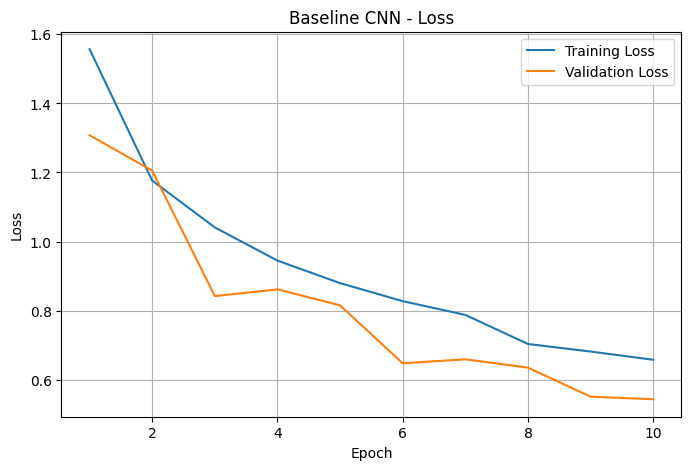

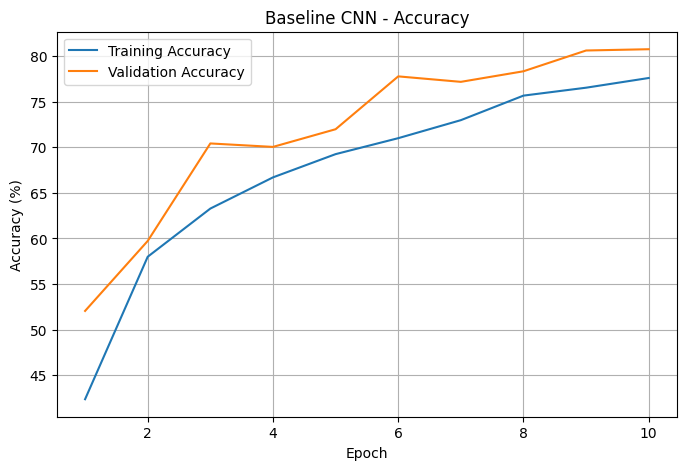

Baseline CNN Test Accuracy: 81.63%


In [ ]:
baseline_model = BaselineCNN()

baseline_history, baseline_checkpoint = train_model(
    model=baseline_model,
    model_name="baseline",
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    optimizer_name="Adam"
)

plot_history(baseline_history, "Baseline CNN")

baseline_model, baseline_checkpoint_data = load_checkpoint_model(
    BaselineCNN(),
    baseline_checkpoint
)

baseline_test_accuracy = evaluate_model(
    baseline_model,
    test_loader
)

print(
    f"Baseline CNN Test Accuracy: "
    f"{baseline_test_accuracy:.2f}%"
)

Step 12 — Residual Block and Residual CNN

In [ ]:
class ResidualBlock(nn.Module):

    def __init__(self, in_channels, out_channels, stride=1):

        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:

            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        else:

            self.shortcut = nn.Identity()

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity
        out = self.relu(out)

        return out


class ResidualCNN(nn.Module):

    def __init__(self, num_classes=10):

        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv2d(
                3, 32,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.layer1 = nn.Sequential(
            ResidualBlock(32, 32),
            ResidualBlock(32, 32)
        )

        self.layer2 = nn.Sequential(
            ResidualBlock(32, 64, stride=2),
            ResidualBlock(64, 64)
        )

        self.layer3 = nn.Sequential(
            ResidualBlock(64, 128, stride=2),
            ResidualBlock(128, 128)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):

        x = self.initial(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x


residual_model = ResidualCNN().to(DEVICE)

sample = torch.randn(4, 3, 32, 32).to(DEVICE)

print(
    "Residual CNN output shape:",
    residual_model(sample).shape
)

Residual CNN output shape: torch.Size([4, 10])


Step 13 — Train Residual CNN

residual | Epoch 1/10 | Train Loss: 1.4448 | Train Acc: 46.56% | Val Loss: 1.2305 | Val Acc: 56.06%
residual | Epoch 2/10 | Train Loss: 1.0309 | Train Acc: 63.18% | Val Loss: 1.3486 | Val Acc: 55.32%
residual | Epoch 3/10 | Train Loss: 0.8576 | Train Acc: 69.70% | Val Loss: 0.8941 | Val Acc: 69.76%
residual | Epoch 4/10 | Train Loss: 0.7341 | Train Acc: 74.48% | Val Loss: 0.6845 | Val Acc: 76.52%
residual | Epoch 5/10 | Train Loss: 0.6521 | Train Acc: 77.61% | Val Loss: 0.6306 | Val Acc: 78.90%
residual | Epoch 6/10 | Train Loss: 0.5921 | Train Acc: 79.61% | Val Loss: 0.6564 | Val Acc: 79.22%
residual | Epoch 7/10 | Train Loss: 0.5385 | Train Acc: 81.70% | Val Loss: 0.5819 | Val Acc: 80.98%
residual | Epoch 8/10 | Train Loss: 0.4516 | Train Acc: 84.43% | Val Loss: 0.4629 | Val Acc: 84.62%
residual | Epoch 9/10 | Train Loss: 0.4166 | Train Acc: 85.82% | Val Loss: 0.4793 | Val Acc: 84.02%
residual | Epoch 10/10 | Train Loss: 0.4001 | Train Acc: 86.38% | Val Loss: 0.4324 | Val Acc: 86.00%

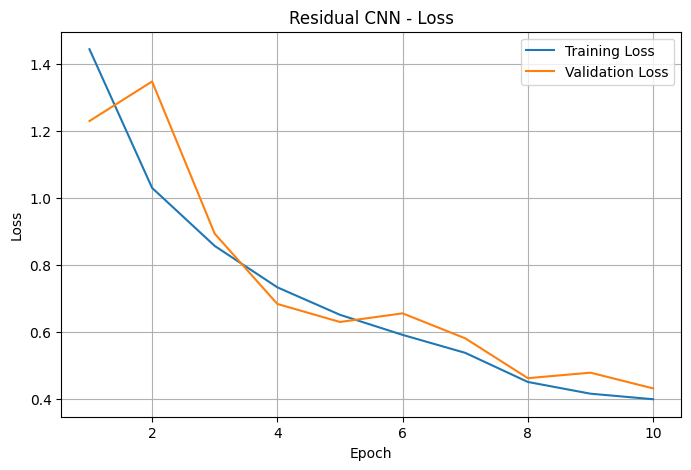

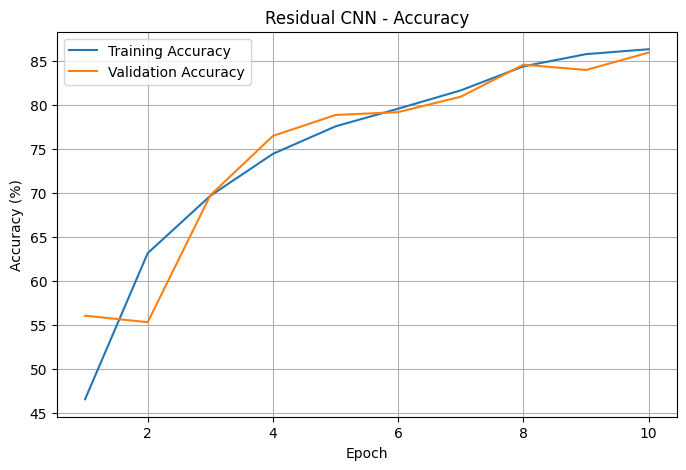

Residual CNN Test Accuracy: 85.59%


In [ ]:
residual_model = ResidualCNN()

residual_history, residual_checkpoint = train_model(
    model=residual_model,
    model_name="residual",
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    optimizer_name="Adam"
)

plot_history(residual_history, "Residual CNN")

residual_model, residual_checkpoint_data = load_checkpoint_model(
    ResidualCNN(),
    residual_checkpoint
)

residual_test_accuracy = evaluate_model(
    residual_model,
    test_loader
)

print(
    f"Residual CNN Test Accuracy: "
    f"{residual_test_accuracy:.2f}%"
)

Step 14 — Hyperparameter tuning

In [ ]:
TUNING_EPOCHS = 3

TUNING_CONFIGS = [

    {
        "name": "baseline_setting",
        "learning_rate": 0.001,
        "batch_size": 64,
        "optimizer": "Adam",
        "dropout_rate": 0.25
    },

    {
        "name": "lower_learning_rate",
        "learning_rate": 0.0005,
        "batch_size": 64,
        "optimizer": "Adam",
        "dropout_rate": 0.25
    },

    {
        "name": "larger_batch_size",
        "learning_rate": 0.001,
        "batch_size": 128,
        "optimizer": "Adam",
        "dropout_rate": 0.25
    },

    {
        "name": "sgd_optimizer",
        "learning_rate": 0.001,
        "batch_size": 64,
        "optimizer": "SGD",
        "dropout_rate": 0.25
    },

    {
        "name": "higher_dropout",
        "learning_rate": 0.001,
        "batch_size": 64,
        "optimizer": "Adam",
        "dropout_rate": 0.40
    }
]

print("Number of tuning experiments:", len(TUNING_CONFIGS))

Number of tuning experiments: 5


Run tuning experiments

In [ ]:
tuning_results = []

for trial_number, config in enumerate(TUNING_CONFIGS, start=1):

    print("\n" + "=" * 60)
    print(f"TRIAL {trial_number}: {config['name']}")
    print("=" * 60)

    trial_train_loader, trial_val_loader = get_loaders(
        config["batch_size"]
    )

    trial_model = BaselineCNN(
        dropout_rate=config["dropout_rate"]
    )

    trial_history, trial_checkpoint = train_model(
        model=trial_model,
        model_name=f"tuning_{config['name']}",
        train_loader=trial_train_loader,
        val_loader=trial_val_loader,
        epochs=TUNING_EPOCHS,
        learning_rate=config["learning_rate"],
        optimizer_name=config["optimizer"]
    )

    best_trial_val_accuracy = max(
        trial_history["val_accuracy"]
    )

    result = {
        **config,
        "best_val_accuracy": best_trial_val_accuracy,
        "checkpoint": trial_checkpoint
    }

    tuning_results.append(result)

    print(
        "Best validation accuracy:",
        f"{best_trial_val_accuracy:.2f}%"
    )


print("\nAll tuning experiments completed.")


TRIAL 1: baseline_setting
tuning_baseline_setting | Epoch 1/3 | Train Loss: 1.5262 | Train Acc: 43.69% | Val Loss: 1.3454 | Val Acc: 52.88%
tuning_baseline_setting | Epoch 2/3 | Train Loss: 1.1515 | Train Acc: 58.59% | Val Loss: 1.0851 | Val Acc: 61.62%
tuning_baseline_setting | Epoch 3/3 | Train Loss: 1.0005 | Train Acc: 64.15% | Val Loss: 0.8754 | Val Acc: 69.42%
Best validation accuracy: 69.42
Checkpoint saved: outputs/checkpoints/best_tuning_baseline_setting.pth
Best validation accuracy: 69.42%

TRIAL 2: lower_learning_rate
tuning_lower_learning_rate | Epoch 1/3 | Train Loss: 1.5325 | Train Acc: 42.86% | Val Loss: 1.1608 | Val Acc: 59.10%
tuning_lower_learning_rate | Epoch 2/3 | Train Loss: 1.1458 | Train Acc: 58.79% | Val Loss: 0.9111 | Val Acc: 66.68%
tuning_lower_learning_rate | Epoch 3/3 | Train Loss: 0.9868 | Train Acc: 64.85% | Val Loss: 0.8695 | Val Acc: 68.86%
Best validation accuracy: 68.86
Checkpoint saved: outputs/checkpoints/best_tuning_lower_learning_rate.pth
Best val

Compare tuning results and select best configuration

In [ ]:
tuning_df = pd.DataFrame([
    {
        "Experiment": r["name"],
        "Learning Rate": r["learning_rate"],
        "Batch Size": r["batch_size"],
        "Optimizer": r["optimizer"],
        "Dropout": r["dropout_rate"],
        "Validation Accuracy (%)": round(
            r["best_val_accuracy"], 2
        )
    }
    for r in tuning_results
])

tuning_df = tuning_df.sort_values(
    "Validation Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(tuning_df)

best_result = max(
    tuning_results,
    key=lambda x: x["best_val_accuracy"]
)

BEST_CONFIG = {
    "learning_rate": best_result["learning_rate"],
    "batch_size": best_result["batch_size"],
    "optimizer": best_result["optimizer"],
    "dropout_rate": best_result["dropout_rate"]
}

print("\nBEST CONFIGURATION")
print("------------------")

for key, value in BEST_CONFIG.items():
    print(f"{key}: {value}")

print(
    "Best validation accuracy:",
    f"{best_result['best_val_accuracy']:.2f}%"
)

,Experiment,Learning Rate,Batch Size,Optimizer,Dropout,Validation Accuracy (%)
0,baseline_setting,0.0010,64,Adam,0.25,69.42
1,lower_learning_rate,0.0005,64,Adam,0.25,68.86
2,higher_dropout,0.0010,64,Adam,0.40,65.26
3,larger_batch_size,0.0010,128,Adam,0.25,65.24
4,sgd_optimizer,0.0010,64,SGD,0.25,55.82



BEST CONFIGURATION
------------------
learning_rate: 0.001
batch_size: 64
optimizer: Adam
dropout_rate: 0.25
Best validation accuracy: 69.42%


Step 15 — Train final tuned CNN

tuned_cnn | Epoch 1/10 | Train Loss: 1.5201 | Train Acc: 43.83% | Val Loss: 1.1935 | Val Acc: 57.58%
tuned_cnn | Epoch 2/10 | Train Loss: 1.1570 | Train Acc: 58.34% | Val Loss: 1.2051 | Val Acc: 59.04%
tuned_cnn | Epoch 3/10 | Train Loss: 1.0050 | Train Acc: 64.52% | Val Loss: 0.8910 | Val Acc: 68.16%
tuned_cnn | Epoch 4/10 | Train Loss: 0.9056 | Train Acc: 68.02% | Val Loss: 0.8208 | Val Acc: 70.82%
tuned_cnn | Epoch 5/10 | Train Loss: 0.8332 | Train Acc: 70.92% | Val Loss: 0.7861 | Val Acc: 72.48%
tuned_cnn | Epoch 6/10 | Train Loss: 0.7890 | Train Acc: 72.42% | Val Loss: 0.7180 | Val Acc: 75.54%
tuned_cnn | Epoch 7/10 | Train Loss: 0.7419 | Train Acc: 74.33% | Val Loss: 0.6209 | Val Acc: 78.86%
tuned_cnn | Epoch 8/10 | Train Loss: 0.6590 | Train Acc: 77.08% | Val Loss: 0.5732 | Val Acc: 80.46%
tuned_cnn | Epoch 9/10 | Train Loss: 0.6310 | Train Acc: 78.18% | Val Loss: 0.5552 | Val Acc: 80.64%
tuned_cnn | Epoch 10/10 | Train Loss: 0.6155 | Train Acc: 78.73% | Val Loss: 0.5482 | Val A

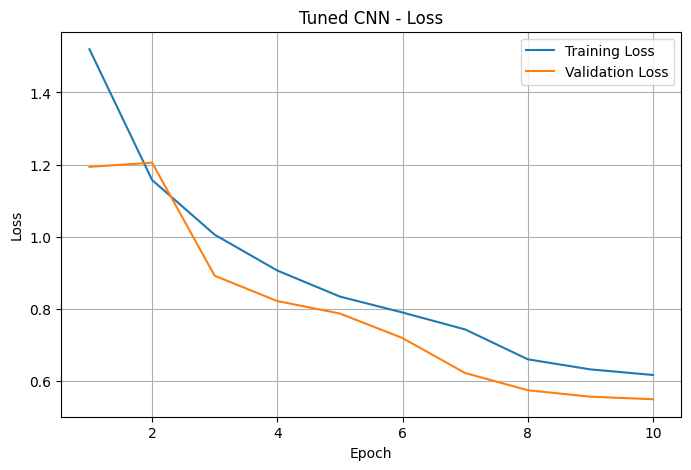

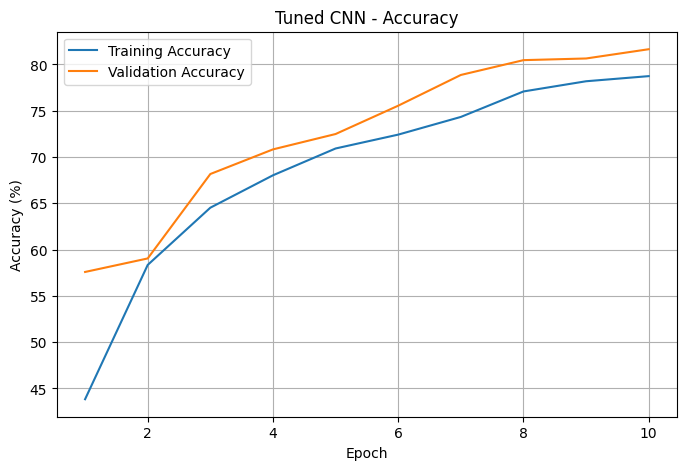

Tuned CNN Test Accuracy: 81.66%


In [ ]:
tuned_train_loader, tuned_val_loader = get_loaders(
    BEST_CONFIG["batch_size"]
)

tuned_model = BaselineCNN(
    dropout_rate=BEST_CONFIG["dropout_rate"]
)

tuned_history, tuned_checkpoint = train_model(
    model=tuned_model,
    model_name="tuned_cnn",
    train_loader=tuned_train_loader,
    val_loader=tuned_val_loader,
    epochs=EPOCHS,
    learning_rate=BEST_CONFIG["learning_rate"],
    optimizer_name=BEST_CONFIG["optimizer"]
)

plot_history(tuned_history, "Tuned CNN")

tuned_model, tuned_checkpoint_data = load_checkpoint_model(
    BaselineCNN(
        dropout_rate=BEST_CONFIG["dropout_rate"]
    ),
    tuned_checkpoint
)

tuned_test_accuracy = evaluate_model(
    tuned_model,
    test_loader
)

print(
    f"Tuned CNN Test Accuracy: "
    f"{tuned_test_accuracy:.2f}%"
)

Step 16 — Early Stopping and Gradient Clipping

In [ ]:
class EarlyStopping:

    def __init__(self, patience=4, min_delta=0.0):

        self.patience = patience
        self.min_delta = min_delta

        self.best_loss = float("inf")
        self.counter = 0
        self.should_stop = False

    def __call__(self, validation_loss):

        if validation_loss < self.best_loss - self.min_delta:

            self.best_loss = validation_loss
            self.counter = 0

        else:

            self.counter += 1

        if self.counter >= self.patience:

            self.should_stop = True

        return self.should_stop


print("EarlyStopping class ready.")

EarlyStopping class ready.


Callback training function

In [ ]:
def train_model_with_callback(
    model,
    model_name,
    train_loader,
    val_loader,
    epochs=10,
    learning_rate=0.001,
    optimizer_name="Adam",
    patience=4,
    gradient_clip_value=1.0
):

    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "Adam":

        optimizer = optim.Adam(
            model.parameters(),
            lr=learning_rate
        )

    elif optimizer_name == "SGD":

        optimizer = optim.SGD(
            model.parameters(),
            lr=learning_rate,
            momentum=0.9
        )

    else:

        raise ValueError("Unsupported optimizer")

    scheduler = optim.lr_scheduler.StepLR(
        optimizer,
        step_size=7,
        gamma=0.5
    )

    early_stopping = EarlyStopping(
        patience=patience
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
        "learning_rate": []
    }

    best_val_loss = float("inf")
    best_epoch = 0

    checkpoint_path = (
        f"outputs/checkpoints/best_{model_name}.pth"
    )

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=gradient_clip_value
            )

            optimizer.step()

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size

            batch_correct, batch_total = calculate_accuracy(
                outputs,
                labels
            )

            correct += batch_correct
            total += batch_total

        train_loss = running_loss / total
        train_acc = 100 * correct / total

        val_loss, val_acc = validate_one_epoch(
            model,
            val_loader,
            criterion
        )

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)
        history["learning_rate"].append(current_lr)

        # Save best validation-loss model
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "val_accuracy": val_acc,
                "model_name": model_name
            }, checkpoint_path)

        print(
            f"{model_name} | "
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

        scheduler.step()

        if early_stopping(val_loss):

            print(
                f"Early stopping triggered at epoch {epoch+1}"
            )

            break

    print("Best validation loss:", round(best_val_loss, 4))
    print("Best epoch:", best_epoch)
    print("Checkpoint:", checkpoint_path)

    return history, checkpoint_path


print("Callback training function ready.")

Callback training function ready.


Step 17 — Train callback-enabled CNN

callback_cnn | Epoch 1/20 | Train Loss: 1.5536 | Train Acc: 42.72% | Val Loss: 1.2255 | Val Acc: 55.98%
callback_cnn | Epoch 2/20 | Train Loss: 1.1906 | Train Acc: 57.20% | Val Loss: 0.9931 | Val Acc: 65.06%
callback_cnn | Epoch 3/20 | Train Loss: 1.0293 | Train Acc: 63.75% | Val Loss: 0.9594 | Val Acc: 67.08%
callback_cnn | Epoch 4/20 | Train Loss: 0.9347 | Train Acc: 67.04% | Val Loss: 0.7869 | Val Acc: 71.98%
callback_cnn | Epoch 5/20 | Train Loss: 0.8556 | Train Acc: 70.07% | Val Loss: 0.7798 | Val Acc: 72.90%
callback_cnn | Epoch 6/20 | Train Loss: 0.8119 | Train Acc: 72.07% | Val Loss: 0.7224 | Val Acc: 75.54%
callback_cnn | Epoch 7/20 | Train Loss: 0.7698 | Train Acc: 73.55% | Val Loss: 0.6434 | Val Acc: 77.92%
callback_cnn | Epoch 8/20 | Train Loss: 0.6806 | Train Acc: 76.47% | Val Loss: 0.5684 | Val Acc: 80.52%
callback_cnn | Epoch 9/20 | Train Loss: 0.6523 | Train Acc: 77.38% | Val Loss: 0.5822 | Val Acc: 80.54%
callback_cnn | Epoch 10/20 | Train Loss: 0.6318 | Train Acc: 78.

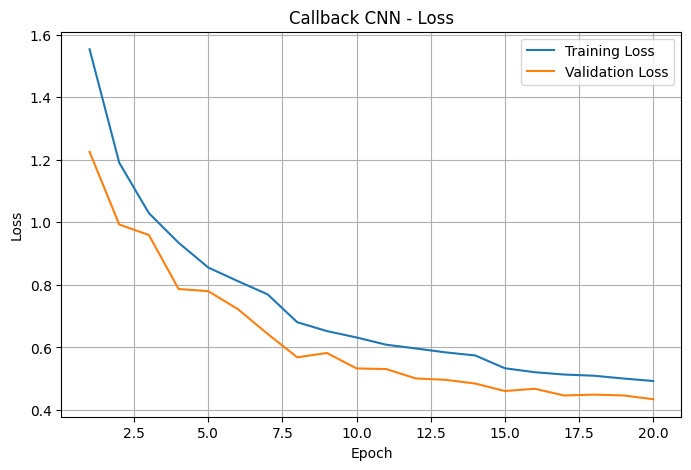

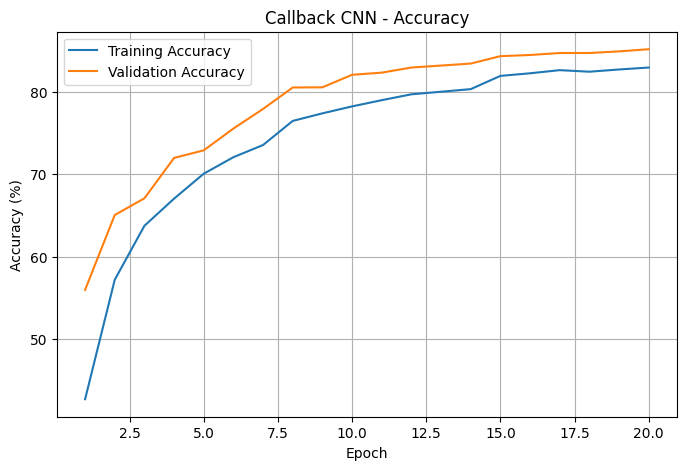

Callback CNN Test Accuracy: 85.56%


In [ ]:
callback_model = BaselineCNN()

callback_history, callback_checkpoint = train_model_with_callback(
    model=callback_model,
    model_name="callback_cnn",
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=20,
    learning_rate=LEARNING_RATE,
    optimizer_name="Adam",
    patience=4,
    gradient_clip_value=1.0
)

plot_history(callback_history, "Callback CNN")

callback_model, callback_checkpoint_data = load_checkpoint_model(
    BaselineCNN(),
    callback_checkpoint
)

callback_test_accuracy = evaluate_model(
    callback_model,
    test_loader
)

print(
    f"Callback CNN Test Accuracy: "
    f"{callback_test_accuracy:.2f}%"
)

Step 18 — Final evaluation: All four models

In [ ]:
# Reload all best checkpoints

baseline_model, _ = load_checkpoint_model(
    BaselineCNN(),
    baseline_checkpoint
)

residual_model, _ = load_checkpoint_model(
    ResidualCNN(),
    residual_checkpoint
)

tuned_model, _ = load_checkpoint_model(
    BaselineCNN(
        dropout_rate=BEST_CONFIG["dropout_rate"]
    ),
    tuned_checkpoint
)

callback_model, _ = load_checkpoint_model(
    BaselineCNN(),
    callback_checkpoint
)


# Evaluate on the same test dataset

baseline_test_accuracy = evaluate_model(
    baseline_model,
    test_loader
)

residual_test_accuracy = evaluate_model(
    residual_model,
    test_loader
)

tuned_test_accuracy = evaluate_model(
    tuned_model,
    test_loader
)

callback_test_accuracy = evaluate_model(
    callback_model,
    test_loader
)


print("FINAL TEST RESULTS")
print("------------------")

print(f"Baseline CNN: {baseline_test_accuracy:.2f}%")
print(f"Residual CNN: {residual_test_accuracy:.2f}%")
print(f"Tuned CNN: {tuned_test_accuracy:.2f}%")
print(f"Callback CNN: {callback_test_accuracy:.2f}%")

FINAL TEST RESULTS
------------------
Baseline CNN: 81.82%
Residual CNN: 85.59%
Tuned CNN: 81.66%
Callback CNN: 85.56%


Step 19 — Final comparison table

In [ ]:
final_comparison = pd.DataFrame({

    "Model / Approach": [
        "Baseline CNN",
        "Residual CNN",
        "Hyperparameter-Tuned CNN",
        "Callback-Enabled CNN"
    ],

    "Test Accuracy (%)": [
        baseline_test_accuracy,
        residual_test_accuracy,
        tuned_test_accuracy,
        callback_test_accuracy
    ]
})

final_comparison = final_comparison.sort_values(
    "Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

final_comparison.insert(
    0,
    "Rank",
    range(1, len(final_comparison) + 1)
)

display(
    final_comparison.style.format({
        "Test Accuracy (%)": "{:.2f}%"
    })
)

,Rank,Model / Approach,Test Accuracy (%)
0,1,Residual CNN,85.59%
1,2,Callback-Enabled CNN,85.56%
2,3,Baseline CNN,81.82%
3,4,Hyperparameter-Tuned CNN,81.66%


Step 20 — Final comparison chart

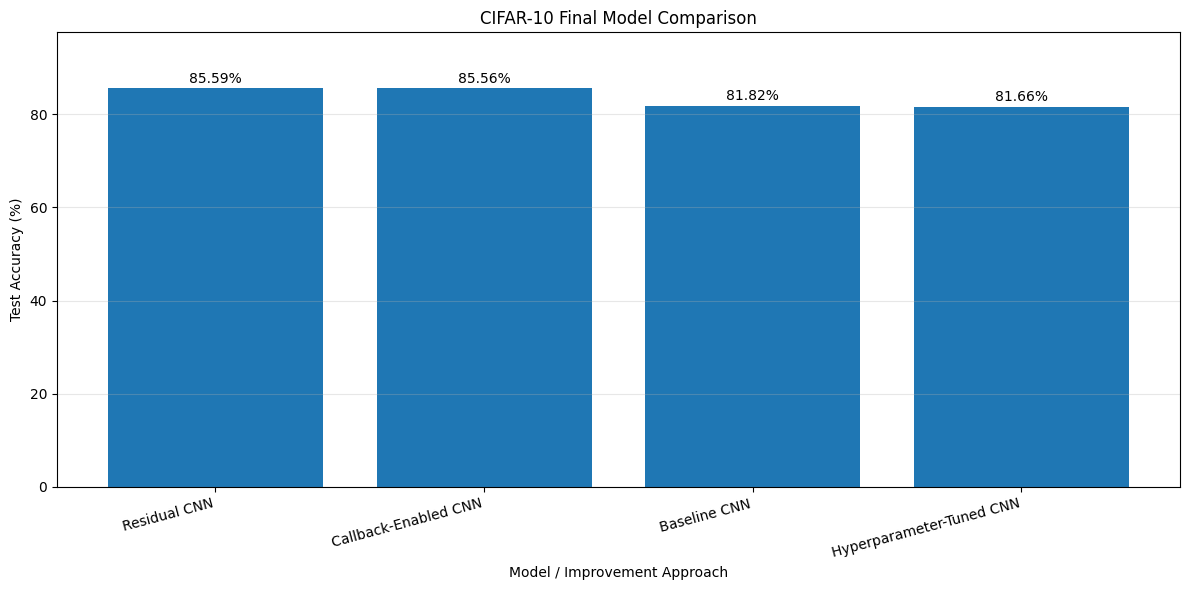

In [ ]:
plt.figure(figsize=(12, 6))

bars = plt.bar(
    final_comparison["Model / Approach"],
    final_comparison["Test Accuracy (%)"]
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.title("CIFAR-10 Final Model Comparison")
plt.xlabel("Model / Improvement Approach")
plt.ylabel("Test Accuracy (%)")

plt.ylim(
    0,
    min(
        100,
        float(final_comparison["Test Accuracy (%)"].max()) + 12
    )
)

plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/plots/final_four_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 21 — Identify the best model

In [ ]:
best_row = final_comparison.iloc[0]

baseline_row = final_comparison[
    final_comparison["Model / Approach"] == "Baseline CNN"
].iloc[0]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_row["Model / Approach"])

print(
    f"Test Accuracy: {best_row['Test Accuracy (%)']:.2f}%"
)

improvement = (
    best_row["Test Accuracy (%)"]
    - baseline_row["Test Accuracy (%)"]
)

print(
    f"Improvement over baseline: {improvement:+.2f} "
    "percentage points"
)

print("\nBEST HYPERPARAMETER CONFIGURATION")

for key, value in BEST_CONFIG.items():

    print(f"{key}: {value}")

BEST PERFORMING MODEL
---------------------
Model: Residual CNN
Test Accuracy: 85.59%
Improvement over baseline: +3.77 percentage points

BEST HYPERPARAMETER CONFIGURATION
learning_rate: 0.001
batch_size: 64
optimizer: Adam
dropout_rate: 0.25


Step 22 — Misclassified image analysis

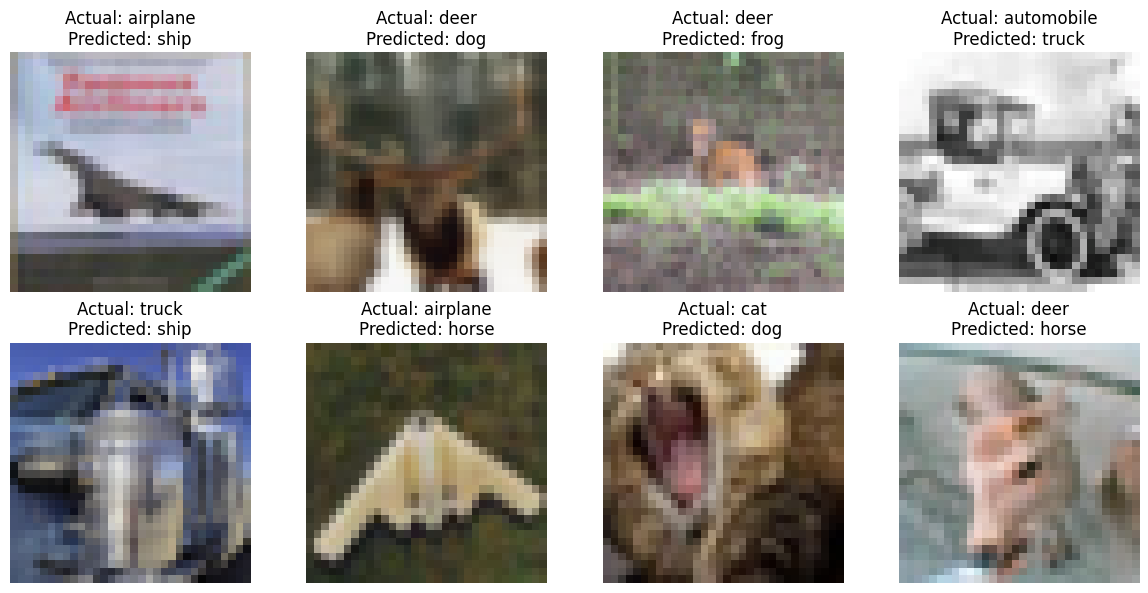

In [ ]:
def show_misclassified(model, loader, max_images=8):

    model.eval()

    wrong_images = []
    actual_labels = []
    predicted_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images_device = images.to(DEVICE)
            labels_device = labels.to(DEVICE)

            outputs = model(images_device)

            predictions = outputs.argmax(dim=1)

            wrong_indices = (
                predictions != labels_device
            ).nonzero(as_tuple=True)[0]

            for idx in wrong_indices:

                wrong_images.append(images[idx].cpu())

                actual_labels.append(
                    labels[idx].item()
                )

                predicted_labels.append(
                    predictions[idx].item()
                )

                if len(wrong_images) >= max_images:
                    break

            if len(wrong_images) >= max_images:
                break

    if len(wrong_images) == 0:

        print("No misclassified images found.")

        return

    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR_STD).view(3, 1, 1)

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))

    for i, ax in enumerate(axes.flat):

        if i >= len(wrong_images):

            ax.axis("off")
            continue

        image = wrong_images[i] * std + mean

        image = image.clamp(0, 1).permute(1, 2, 0).numpy()

        ax.imshow(image)

        ax.set_title(
            f"Actual: {CLASS_NAMES[actual_labels[i]]}\n"
            f"Predicted: {CLASS_NAMES[predicted_labels[i]]}"
        )

        ax.axis("off")

    plt.tight_layout()

    plt.savefig(
        "outputs/plots/best_model_misclassified.png",
        dpi=150
    )

    plt.show()


best_name = best_row["Model / Approach"]

if best_name == "Baseline CNN":

    best_visual_model = baseline_model

elif best_name == "Residual CNN":

    best_visual_model = residual_model

elif best_name == "Hyperparameter-Tuned CNN":

    best_visual_model = tuned_model

else:

    best_visual_model = callback_model


show_misclassified(
    best_visual_model,
    test_loader
)

Step 23 — Save results and download project outputs

In [ ]:
# Save final comparison
final_comparison.to_csv(
    "outputs/final_model_comparison.csv",
    index=False
)

# Save tuning results
tuning_df.to_csv(
    "outputs/hyperparameter_tuning_results.csv",
    index=False
)

# Save selected hyperparameters
pd.DataFrame(
    [BEST_CONFIG]
).to_csv(
    "outputs/best_hyperparameters.csv",
    index=False
)

# Create ZIP archive
zip_path = shutil.make_archive(
    "cifar10_project_outputs",
    "zip",
    root_dir="outputs"
)

print("Project outputs saved successfully.")
print("Final comparison:", "outputs/final_model_comparison.csv")
print("Tuning results:", "outputs/hyperparameter_tuning_results.csv")
print("Best parameters:", "outputs/best_hyperparameters.csv")
print("ZIP file:", zip_path)

try:

    from google.colab import files

    files.download(zip_path)

except ImportError:

    print("Not running in Google Colab.")

Project outputs saved successfully.
Final comparison: outputs/final_model_comparison.csv
Tuning results: outputs/hyperparameter_tuning_results.csv
Best parameters: outputs/best_hyperparameters.csv
ZIP file: /content/cifar10_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 24 — Final verification

In [ ]:
# Check all required results exist

assert len(tuning_results) == len(TUNING_CONFIGS)

assert len(final_comparison) == 4

assert os.path.exists(baseline_checkpoint)
assert os.path.exists(residual_checkpoint)
assert os.path.exists(tuned_checkpoint)
assert os.path.exists(callback_checkpoint)

assert final_comparison["Test Accuracy (%)"].notna().all()

print("All verification checks passed.")

print("\nFinal project summary:")
print("Dataset: CIFAR-10")
print("Classes:", NUM_CLASSES)
print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Testing images:", len(test_dataset))
print("Models evaluated:", len(final_comparison))

print("\nProject completed successfully.")

All verification checks passed.

Final project summary:
Dataset: CIFAR-10
Classes: 10
Training images: 45000
Validation images: 5000
Testing images: 10000
Models evaluated: 4

Project completed successfully.


Step 25 — Create README and requirements files

In [ ]:
requirements = """
torch
torchvision
numpy
pandas
matplotlib
"""

with open("outputs/requirements.txt", "w") as f:
    f.write(requirements.strip())


readme = f"""
# CIFAR-10 Image Classification

## Objective
Build and compare CNN-based image classification models using PyTorch.

## Dataset
CIFAR-10 contains 60,000 color images across 10 classes.

- Training: 45,000 images
- Validation: 5,000 images
- Testing: 10,000 images

## Models

1. Baseline CNN
2. Residual CNN
3. Hyperparameter-Tuned CNN
4. Callback-Enabled CNN

## Techniques

- Image normalization
- Random crop and horizontal flip augmentation
- Batch normalization
- Dropout
- Adam and SGD optimizers
- Learning rate scheduling
- Hyperparameter tuning
- Early stopping
- Gradient clipping
- Model checkpointing

## Best Hyperparameters

{BEST_CONFIG}

## Final Test Results

{final_comparison.to_string(index=False)}

## How to Run

1. Open the notebook in Google Colab.
2. Select Runtime -> Change runtime type -> GPU.
3. Run all cells from top to bottom.
4. Check the outputs folder for saved results.

## Requirements

See requirements.txt.
"""

with open("outputs/README.md", "w") as f:
    f.write(readme)

print("README.md created.")
print("requirements.txt created.")

README.md created.
requirements.txt created.
